In [3]:
import pandas as pd
from pathlib import Path

# Create sample sales data
sales_data = {
    "Order_ID": [1001, 1002, 1003, 1004, 1005,
                 1006, 1007, 1008, 1009, 1010],

    "Order_Date": [
        "2026-01-05", "2026-01-08", "2026-01-12",
        "2026-02-02", "2026-02-10", "2026-02-15",
        "2026-03-01", "2026-03-08", "2026-03-15",
        "2026-03-20"
    ],

    "Product": [
        "Laptop", "Mouse", "Keyboard", "Laptop", "Mouse",
        "Monitor", "Keyboard", "Laptop", "Monitor", "Mouse"
    ],

    "Category": [
        "Electronics", "Accessories", "Accessories",
        "Electronics", "Accessories", "Electronics",
        "Accessories", "Electronics", "Electronics",
        "Accessories"
    ],

    "Unit_Price": [
        50000, 800, 1500, 52000, 1000,
        12000, 1800, 49000, 12500, 900
    ],

    "Quantity": [2, 5, 3, 1, 8, 2, 4, 1, 3, 6],

    "Region": [
        "Chennai", "Bengaluru", "Chennai", "Mumbai",
        "Chennai", "Bengaluru", "Mumbai", "Chennai",
        "Bengaluru", "Mumbai"
    ]
}

sales_df = pd.DataFrame(sales_data)

# Create the raw data folder if necessary
data_folder = Path("data/raw")
data_folder.mkdir(parents=True, exist_ok=True)

# Save the data as a CSV file
sales_df.to_csv(data_folder / "sales.csv", index=False)

print("Sales dataset created successfully!")
print(sales_df)

Sales dataset created successfully!
   Order_ID  Order_Date   Product     Category  Unit_Price  Quantity  \
0      1001  2026-01-05    Laptop  Electronics       50000         2   
1      1002  2026-01-08     Mouse  Accessories         800         5   
2      1003  2026-01-12  Keyboard  Accessories        1500         3   
3      1004  2026-02-02    Laptop  Electronics       52000         1   
4      1005  2026-02-10     Mouse  Accessories        1000         8   
5      1006  2026-02-15   Monitor  Electronics       12000         2   
6      1007  2026-03-01  Keyboard  Accessories        1800         4   
7      1008  2026-03-08    Laptop  Electronics       49000         1   
8      1009  2026-03-15   Monitor  Electronics       12500         3   
9      1010  2026-03-20     Mouse  Accessories         900         6   

      Region  
0    Chennai  
1  Bengaluru  
2    Chennai  
3     Mumbai  
4    Chennai  
5  Bengaluru  
6     Mumbai  
7    Chennai  
8  Bengaluru  
9     Mumbai  


In [4]:
sales_df = pd.read_csv("data/raw/sales.csv")

print("Dataset shape:", sales_df.shape)
print("\nColumn names:")
print(sales_df.columns.tolist())

print("\nFirst five records:")
print(sales_df.head())

Dataset shape: (10, 7)

Column names:
['Order_ID', 'Order_Date', 'Product', 'Category', 'Unit_Price', 'Quantity', 'Region']

First five records:
   Order_ID  Order_Date   Product     Category  Unit_Price  Quantity  \
0      1001  2026-01-05    Laptop  Electronics       50000         2   
1      1002  2026-01-08     Mouse  Accessories         800         5   
2      1003  2026-01-12  Keyboard  Accessories        1500         3   
3      1004  2026-02-02    Laptop  Electronics       52000         1   
4      1005  2026-02-10     Mouse  Accessories        1000         8   

      Region  
0    Chennai  
1  Bengaluru  
2    Chennai  
3     Mumbai  
4    Chennai  


In [5]:
import pandas as pd
from pathlib import Path

# Load the raw dataset
df = pd.read_csv("data/raw/sales.csv")

# Check data quality
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Convert order date into datetime format
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

# Remove exact duplicate rows, if any
df = df.drop_duplicates()

# Remove rows with invalid or missing essential values
df = df.dropna(
    subset=["Order_ID", "Order_Date", "Product",
            "Category", "Unit_Price", "Quantity", "Region"]
)

# Validate numeric values
df = df[
    (df["Unit_Price"] >= 0) &
    (df["Quantity"] > 0)
].copy()

# Create revenue column
df["Revenue"] = df["Unit_Price"] * df["Quantity"]

# Save cleaned data
Path("data/processed").mkdir(parents=True, exist_ok=True)
df.to_csv("data/processed/cleaned_sales.csv", index=False)

print("\nCleaned dataset:")
print(df.head())
print("\nTotal records:", len(df))
print("Total revenue: ₹", df["Revenue"].sum())

Missing values:
 Order_ID      0
Order_Date    0
Product       0
Category      0
Unit_Price    0
Quantity      0
Region        0
dtype: int64
Duplicate rows: 0

Cleaned dataset:
   Order_ID Order_Date   Product     Category  Unit_Price  Quantity  \
0      1001 2026-01-05    Laptop  Electronics       50000         2   
1      1002 2026-01-08     Mouse  Accessories         800         5   
2      1003 2026-01-12  Keyboard  Accessories        1500         3   
3      1004 2026-02-02    Laptop  Electronics       52000         1   
4      1005 2026-02-10     Mouse  Accessories        1000         8   

      Region  Revenue  
0    Chennai   100000  
1  Bengaluru     4000  
2    Chennai     4500  
3     Mumbai    52000  
4    Chennai     8000  

Total records: 10
Total revenue: ₹ 291600


In [6]:
# Overall KPIs
total_revenue = df["Revenue"].sum()
total_orders = df["Order_ID"].nunique()
total_units = df["Quantity"].sum()
average_order_value = total_revenue / total_orders if total_orders else 0

print("Total Revenue: ₹", total_revenue)
print("Total Orders:", total_orders)
print("Units Sold:", total_units)
print("Average Revenue per Order: ₹", round(average_order_value, 2))

# Revenue by product
print("\nRevenue by Product:")
print(df.groupby("Product")["Revenue"].sum().sort_values(ascending=False))

# Revenue by region
print("\nRevenue by Region:")
print(df.groupby("Region")["Revenue"].sum().sort_values(ascending=False))

# Monthly revenue
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)
print("\nMonthly Revenue:")
print(df.groupby("Month")["Revenue"].sum())

Total Revenue: ₹ 291600
Total Orders: 10
Units Sold: 35
Average Revenue per Order: ₹ 29160.0

Revenue by Product:
Product
Laptop      201000
Monitor      61500
Mouse        17400
Keyboard     11700
Name: Revenue, dtype: int64

Revenue by Region:
Region
Chennai      161500
Bengaluru     65500
Mumbai        64600
Name: Revenue, dtype: int64

Monthly Revenue:
Month
2026-01    108500
2026-02     84000
2026-03     99100
Name: Revenue, dtype: int64


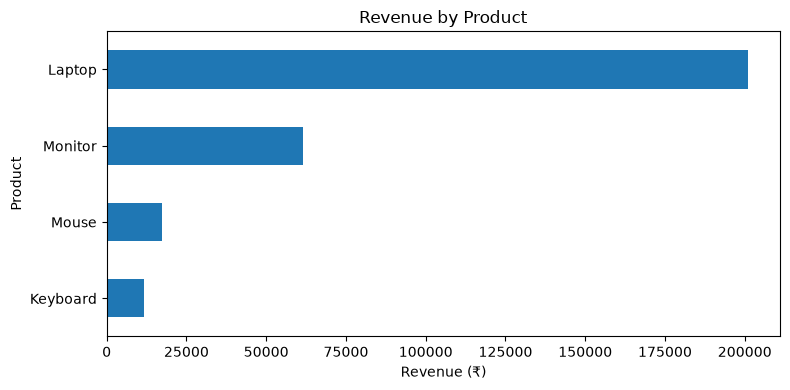

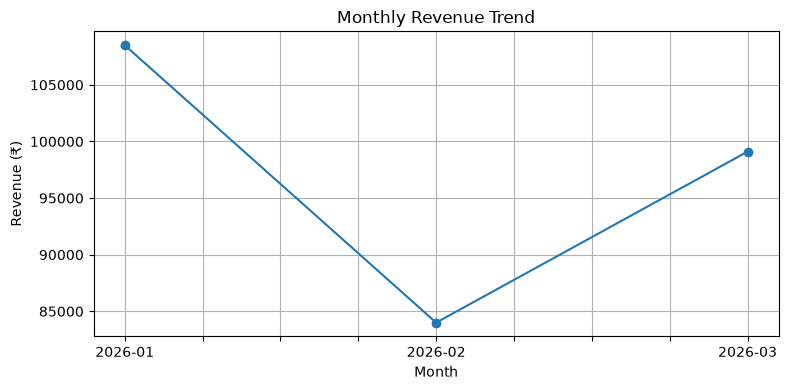

In [7]:
import matplotlib.pyplot as plt

# Product revenue chart
product_revenue = df.groupby("Product")["Revenue"].sum().sort_values()

product_revenue.plot(kind="barh", figsize=(8, 4))
plt.title("Revenue by Product")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# Monthly revenue chart
monthly_revenue = df.groupby("Month")["Revenue"].sum()

monthly_revenue.plot(kind="line", marker="o", figsize=(8, 4))
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.grid(True)
plt.tight_layout()
plt.show()